https://arxiv.org/abs/2509.10619

In [1]:
import sys

!which {sys.executable}

/ut3/jerome/miniconda3/envs/wakai/bin/python


In [2]:
import sys
sys.path.insert(0, '..')

# cross-match Kunimoto+2025 PC with GaiaDR3

In [3]:
from astropy.table import Table
import astropy.io.ascii as ascii

url='https://content.cld.iop.org/journals/1538-3881/170/5/280/revision1/ajae070at4_mrt.txt'
tab = Table.read(url, format='ascii.mrt')
df_pc = tab.to_pandas()
df_pc

Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (60)

,TIC,TOI,CTOI,Comment,SNR,FPP,NFPP,APP0,FP-Reliability,FA-Reliability,Score
0,4487172,NaN,NaN,---,9.56,0.0074,0.0000,0.8347,0.993,0.902,0.467
1,4619242,5295.01,NaN,APC,27.61,0.1113,0.0000,1.0000,0.889,1.000,0.999
2,7439480,6110.01,NaN,PC,25.32,0.0777,0.0463,0.6184,0.939,1.000,1.000
3,12421862,198.01,NaN,CP,14.59,0.0151,0.0000,0.9178,0.985,1.000,0.766
4,12999193,NaN,1.299919e+07,Best Candidate,30.18,0.0023,0.0000,1.0000,0.998,1.000,0.999
...,...,...,...,...,...,...,...,...,...,...,...
167,458419328,3785.01,NaN,CP,25.61,0.0140,0.0000,1.0000,0.986,1.000,1.000
168,459762279,5573.01,NaN,PC,20.25,0.0587,0.0006,0.9766,0.942,1.000,1.000
169,459969497,NaN,4.599695e+08,Best Candidate,15.34,0.5231,0.0000,1.0000,0.477,1.000,0.879
170,467179528,1266.01,NaN,CP,33.76,0.0672,0.0000,1.0000,0.933,1.000,0.999


## match 3d separation with cluster core

In [4]:
from astroquery.mast import Catalogs
import numpy as np

# Query the TIC catalog for these IDs
# We specifically want the 'GAIA' column which contains the Gaia DR2/DR3 source_id
tic_data = Catalogs.query_criteria(catalog="TIC", ID=df_pc['TIC'].unique())

In [5]:
import pandas as pd

df_gaia = tic_data.to_pandas()[['ID','GAIA','ra','dec','plx','pmRA','pmDEC']].astype(float)
df_gaia['TIC'] = df_gaia.ID.copy()
df_pc = pd.merge(df_pc, df_gaia, on='TIC')
df_pc.shape

(172, 18)

In [6]:
from astroquery.gaia import Gaia

# Extract unique Gaia IDs and remove masked/null values
gaia_ids = [int(gid) for gid in tic_data['GAIA'] if gid is not np.ma.masked]

# Format the IDs for the SQL 'IN' clause
ids_str = ",".join(map(str, gaia_ids))

# ADQL query to get source_id and radial_velocity
query = f"""
SELECT source_id, radial_velocity, radial_velocity_error
FROM gaiadr3.gaia_source
WHERE source_id IN ({ids_str})
"""

# Launch the job
job = Gaia.launch_job_async(query)
results = job.get_results()

INFO: Query finished. [astroquery.utils.tap.core]


In [7]:
df_rv = results.to_pandas().astype(float).rename({
    'SOURCE_ID': 'GAIA',
    }, axis=1
                                  )
df_pc = pd.merge(df_pc, df_rv, on='GAIA')

In [8]:
df_pc = df_pc.rename({
        "GAIA": "GaiaDR3",
        "pmRA": "pmra",
        "pmDEC": "pmdec",
        "plx": "parallax",
        "RV": "radial_velocity"
        
    }, axis=1)
df_pc.head()

,TIC,TOI,CTOI,Comment,SNR,FPP,NFPP,APP0,FP-Reliability,FA-Reliability,Score,ID,GaiaDR3,ra,dec,parallax,pmra,pmdec,radial_velocity,radial_velocity_error
0,4487172,NaN,NaN,---,9.56,0.0074,0.0000,0.8347,0.993,0.902,0.467,4487172.0,8.816425e+17,117.057888,32.177662,7.27521,-17.8503,-41.3553,11.439859,2.918459
1,4619242,5295.01,NaN,APC,27.61,0.1113,0.0000,1.0000,0.889,1.000,0.999,4619242.0,2.437966e+18,349.288664,-9.435078,NaN,53.0600,-142.8500,-15.631107,2.809759
2,7439480,6110.01,NaN,PC,25.32,0.0777,0.0463,0.6184,0.939,1.000,1.000,7439480.0,6.172970e+18,212.929488,-29.975047,8.14931,-78.5996,24.8697,15.343903,10.414121
3,12999193,NaN,12999193.01,Best Candidate,30.18,0.0023,0.0000,1.0000,0.998,1.000,0.999,12999193.0,6.606474e+18,346.856710,-28.353978,20.44480,125.8310,118.6870,-78.293701,8.607205
4,16005254,5344.01,NaN,PC,28.70,0.0714,0.0000,1.0000,0.929,1.000,0.991,16005254.0,5.235954e+16,63.266031,20.915252,7.19927,40.2910,-22.0198,44.998318,2.626212


# Perren+2023 catalog

In [9]:
import pandas as pd

catalog_name = 'Perren2023'
df = pd.read_csv('../data/Perren2023/UCC_cat.csv')
df.tail()

,Name(s),name,N_50,r_50,RA_ICRS,DE_ICRS,GLON,GLAT,Plx,pmRA,...,Mass_[Msun],Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc
18264,XDOCC 10,xdocc10,23.0,7.4,305.52488,37.23809,75.66132,0.15836,0.5007,-2.4023,...,655.0,NaN,0.29,NaN,NaN,NaN,AA,0.0,0.25,n
18265,XDOCC 11,xdocc11,54.0,4.3,317.73684,47.70377,89.41856,-0.28394,0.4536,-1.0068,...,591.0,NaN,0.29,NaN,NaN,NaN,AB,0.8,0.09,n
18266,Zanin 6,zanin6,24.0,39.4,342.91235,41.33289,99.92967,-16.14552,2.6838,5.9365,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.0,0.08,y
18267,Zeta Gemini,zetagemini,19.0,8.0,105.96593,20.56051,195.72326,11.87995,0.2679,-0.7368,...,NaN,NaN,NaN,NaN,NaN,NaN,BC,0.0,0.09,y
18268,ZHBJZ 1,zhbjz1,243.0,47.5,103.73696,-5.89465,218.61444,-1.85052,3.4866,-7.4140,...,282.0,166.0,NaN,NaN,NaN,NaN,AA,1.0,0.00,n


In [10]:
df = df.rename({"name": "Name",
                #"Source": "GaiaDR3",
                "probs": "Prob",
                "RA_ICRS": "ra",
                "DE_ICRS": "dec",
                "pmRA": "pmra",
                "pmDE": "pmdec",
                "Plx": "parallax",
                "RV": "radial_velocity"
                }, axis=1)

In [11]:
df_mem = pd.read_parquet('../data/Perren2023/UCC_members.parquet')
df_mem.tail()

,name,Source,RA_ICRS,DE_ICRS,Plx,e_Plx,pmRA,e_pmRA,pmDE,e_pmDE,RV,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,probs
1095681,zhbjz1,3101181101717965312,104.13589,-5.48616,3.4796,0.0468,-7.6025,0.0414,-2.4144,0.0409,NaN,NaN,218.39623,-1.36721,15.6225,2.8157,0.0029,0.0131,1.000
1095682,zhbjz1,3100956320310482048,104.53184,-5.89465,3.5259,0.0222,-7.7372,0.0278,-2.5817,0.0294,16.6076,5.3441,218.93959,-1.20291,14.2556,1.7210,0.0031,0.0085,1.000
1095683,zhbjz1,3101226185994403968,103.65533,-5.53413,3.5530,0.0537,-7.2244,0.0599,-2.6371,0.0526,NaN,NaN,218.22092,-1.81488,16.4796,2.7865,0.0038,0.0253,1.000
1095684,zhbjz1,3101094072800870400,103.15896,-5.98809,3.6033,0.1457,-7.2640,0.1371,-2.6682,0.1321,NaN,NaN,218.40071,-2.46118,17.4554,3.3142,0.0032,0.0574,0.921
1095685,zhbjz1,3100740511096457984,104.27646,-6.89400,3.3414,0.0949,-7.2711,0.0969,-2.0291,0.0745,NaN,NaN,219.71357,-1.88447,17.2505,2.8632,0.0030,0.0292,0.843


In [12]:
#replace name to be compatible with other catalogs' naming formats
df_mem = df_mem.rename({"name": "Name",
                        "Source": "GaiaDR3",
                        "probs": "Prob",
                        "RA_ICRS": "ra",
                        "DE_ICRS": "dec",
                        "pmRA": "pmra",
                        "pmDE": "pmdec",
                        "Plx": "parallax",
                        "RV": "radial_velocity"
                        }, axis=1)
df_mem.shape

(1095686, 19)

In [13]:
idx = df_mem.GaiaDR3.isin(df_pc.GaiaDR3)
idx.sum()

np.int64(3)

In [14]:
df_mem[idx]

,Name,GaiaDR3,ra,dec,parallax,e_Plx,pmra,e_pmRA,pmdec,e_pmDE,radial_velocity,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,Prob
342578,feigelson1,5838183443852841216,182.72617,-75.13193,9.7882,0.0197,-39.3370,0.0215,-7.4589,0.0233,12.8054,3.3098,300.28187,-12.46913,14.4595,3.2021,0.0028,0.0067,1.0
458808,hsc1900,4827527233363019776,79.00509,-31.41269,18.6487,0.0184,34.2857,0.0180,-0.7944,0.0194,NaN,NaN,234.36977,-33.01301,13.7819,3.0490,0.0028,0.0063,1.0
511311,hyades,3311804515502788352,63.27395,15.24770,22.3572,0.0308,122.4495,0.0383,-18.6034,0.0264,42.9187,4.1052,178.25573,-25.29267,14.3554,2.9614,0.0028,0.0083,1.0


In [15]:
idx = df_pc.GaiaDR3.isin(df_mem.GaiaDR3)
idx.sum()

np.int64(3)

In [16]:
df_pc[idx]

,TIC,TOI,CTOI,Comment,SNR,FPP,NFPP,APP0,FP-Reliability,FA-Reliability,Score,ID,GaiaDR3,ra,dec,parallax,pmra,pmdec,radial_velocity,radial_velocity_error
26,77951245,450.01,NaN,APC,118.69,0.9999,0.0000,1.0000,0.000,1.0,0.966,77951245.0,4.827527e+18,79.004915,-31.412691,18.66060,34.2463,-0.734815,NaN,NaN
136,359357695,1880.01,NaN,PC,29.47,0.9042,0.3683,0.5801,0.138,1.0,1.000,359357695.0,5.838183e+18,182.726848,-75.131898,9.71749,-39.4012,-7.249750,12.805389,3.309779
156,434226736,5095.01,NaN,KP,12.85,0.6887,0.0000,0.9995,0.311,1.0,0.992,434226736.0,3.311805e+18,63.273389,15.247782,22.21530,122.1480,-18.337100,42.918736,4.105148


In [17]:
from astropy.coordinates import SkyCoord, Distance
import astropy.units as u

coords1 = SkyCoord(ra=df_pc['ra'].values*u.degree, 
                   dec=df_pc['dec'].values*u.degree, 
                   distance=Distance(parallax=df_pc['parallax'].values* u.mas, allow_negative=True),
                   frame='icrs')
coords2 = SkyCoord(ra=df['ra'].values*u.degree, 
                   dec=df['dec'].values*u.degree, 
                   distance=Distance(parallax=df['parallax'].values* u.mas, allow_negative=True),
                   frame='icrs') 

idx, d2d, d3d = coords1.match_to_catalog_sky(coords2)

df_pc['sep2d_arcsec'] = d2d.to(u.arcsec).value
df_pc['sep3d_pc'] = d3d.to(u.pc).value
df_pc.sort_values('sep2d_arcsec').head()

,TIC,TOI,CTOI,Comment,SNR,FPP,NFPP,APP0,FP-Reliability,FA-Reliability,...,GaiaDR3,ra,dec,parallax,pmra,pmdec,radial_velocity,radial_velocity_error,sep2d_arcsec,sep3d_pc
143,387690507,530.01,NaN,CP,16.88,0.2255,0.1766,1.0000,0.941,1.000,...,3.353219e+18,103.412773,12.881848,6.69383,13.6816,-62.5767,-34.350132,4.599171,533.610036,1954.543590
107,284441182,1470.01,NaN,CP,10.72,0.0951,0.0003,1.0000,0.905,0.947,...,4.272241e+17,10.088709,61.213626,19.22020,48.5759,-55.6022,3.536417,0.504362,553.388627,1247.685663
135,359271092,741.01,NaN,PC,13.03,0.0174,0.0004,0.7816,0.983,1.000,...,5.299440e+18,140.406672,-60.281953,95.62790,-840.1140,182.0900,39.588486,0.144154,553.785544,4443.885823
154,422756130,1695.01,NaN,CP,16.52,0.1482,0.0000,0.9616,0.852,1.000,...,5.349886e+17,21.920719,72.296441,22.12890,71.7067,40.4748,-59.988258,0.430977,669.099043,5425.269984
44,146776480,2605.01,NaN,APC,45.90,0.2518,0.0000,0.9999,0.748,1.000,...,5.546355e+18,124.355025,-34.464643,27.53060,299.3120,-513.1990,84.546265,3.086514,746.008815,6879.306343


In [18]:
import sys
sys.path.insert(0, '..')
from wakai.catalog import get_cluster_3d_size

# test on praesepe
d = df_mem.groupby('Name').get_group('ic2602')
get_cluster_3d_size(d)

np.float64(56.72352784737517)

In [19]:
# apply func to all clusters
df_size = df_mem.groupby('Name').apply(get_cluster_3d_size)

/ut3/jerome/miniconda3/envs/wakai/lib/python3.12/site-packages/astropy/units/equivalencies.py:100: RuntimeWarning: divide by zero encountered in divide
  d = 1 / x
/tmp/ipykernel_941091/3100306159.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_size = df_mem.groupby('Name').apply(get_cluster_3d_size)


In [20]:
df = df.merge(df_size.reset_index(name='extent_pc'), on='Name')
df.head()

,Name(s),Name,N_50,r_50,ra,dec,GLON,GLAT,parallax,pmra,...,Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc,extent_pc
0,ADS 12696,ads12696,11.0,6.7,294.31735,29.33689,64.00852,3.97490,0.1604,-2.4837,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.03,y,13562.040379
1,ADS 13292,ads13292,83.0,1.0,300.59778,35.31288,71.86015,2.42440,0.5153,-3.3527,...,NaN,NaN,NaN,NaN,NaN,AB,0.24,0.37,n,1932.852329
2,ADS 16795;AR Cas,ads16795,25.0,88.7,351.39010,58.44167,111.87712,-2.57522,4.4213,19.1632,...,NaN,NaN,NaN,NaN,NaN,CC,0.00,0.18,y,47.716982
3,AFGL333,afgl333,21.0,6.9,37.28676,61.47758,134.31242,0.77933,0.4389,-1.1749,...,NaN,NaN,NaN,NaN,NaN,BB,0.00,0.14,y,1600.637192
4,AFGL4029,afgl4029,30.0,3.9,45.20529,60.54280,138.20570,1.56202,0.4398,-0.1279,...,NaN,NaN,NaN,NaN,NaN,DC,0.47,0.14,n,1374.376330


In [21]:
# Add a prefix to matched columns to avoid confusion (optional but recommended)
col_prefix = 'matched_'
df_matched_tic = df.iloc[idx].copy().add_prefix(col_prefix)

# Concatenate horizontally
df_match = pd.concat([df_pc.reset_index(drop=True), 
                      df_matched_tic.reset_index(drop=True)
                      ], axis=1)

In [22]:
# make sure the 3d sep from cluster core is smaller the spatial extent of that cluster
idx2 = df_match[f'{col_prefix}extent_pc'] > df_match['sep3d_pc']
df_match[idx2]

,TIC,TOI,CTOI,Comment,SNR,FPP,NFPP,APP0,FP-Reliability,FA-Reliability,...,matched_Mass_STDDEV,matched_Binary_fr,matched_Binary_fr_STDDEV,matched_BSS,matched_BSS_STDDEV,matched_C3,matched_P_dup,matched_UTI,matched_bad_oc,matched_extent_pc
2,7439480,6110.01,NaN,PC,25.32,0.0777,0.0463,0.6184,0.939,1.000,...,NaN,NaN,NaN,NaN,NaN,CC,0.00,0.11,y,10952.758172
5,19028197,5094.01,NaN,KP,135.45,0.0000,0.0000,0.9999,1.000,1.000,...,NaN,NaN,NaN,NaN,NaN,CD,0.00,0.28,n,3838.405784
7,22233480,4438.01,NaN,CP,23.52,0.0469,0.0000,0.9991,0.953,1.000,...,NaN,NaN,NaN,NaN,NaN,DD,0.00,0.06,y,5778.258114
10,26279192,NaN,NaN,---,9.50,0.0437,0.0209,0.8064,0.975,0.788,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.20,n,13354.282694
11,27649847,521.01,NaN,PC,16.75,0.0166,0.0000,1.0000,0.983,1.000,...,NaN,NaN,NaN,NaN,NaN,CD,0.00,0.28,n,3838.405784
12,33521996,468.01,NaN,KP,58.89,0.0006,0.0000,1.0000,0.999,1.000,...,NaN,NaN,NaN,NaN,NaN,AB,0.03,0.28,n,38.471554
22,71347873,2293.01,NaN,PC,13.33,0.0364,0.0000,0.5795,0.964,1.000,...,NaN,NaN,NaN,NaN,NaN,CC,0.00,0.21,y,13119.221952
23,73649615,756.01,NaN,PC,11.64,0.2759,0.2424,0.9755,0.951,1.000,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.10,y,18992.116919
26,77951245,450.01,NaN,APC,118.69,0.9999,0.0000,1.0000,0.000,1.000,...,NaN,NaN,NaN,NaN,NaN,BC,0.00,0.24,y,31.950919
43,144077896,6578.01,NaN,PC,10.20,0.0561,0.0000,0.9911,0.944,0.947,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.09,y,8716.688699


In [23]:
df_match['pm_diff'] =  np.sqrt((df_match[f'{col_prefix}pmra'] - df_match[f'{col_prefix}pmdec'])**2 + 
                               (df_match['pmra'] - df_match['pmdec'])**2)


In [24]:
idx3 = df_match[idx2]['pm_diff'] < 10
cols = ['TIC','matched_Name','matched_Age_[Myr]',
        'matched_extent_pc','sep3d_pc','pm_diff','GaiaDR3']
df_final = df_match[idx2].loc[idx3,cols]
df_final

,TIC,matched_Name,matched_Age_[Myr],matched_extent_pc,sep3d_pc,pm_diff,GaiaDR3
11,27649847,alessi165,NaN,3838.405784,1731.080237,9.734817,6.498528e+17
126,333741105,fsr1705,NaN,92586.472748,3488.819665,4.700206,5.907860e+18
131,353475866,cwnu3177,398.0,25666.781501,4631.183481,5.302336,3.451909e+18


Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Plotted 25 stars. Target(s): None


Text(0.5, 0.98, 'TIC-27649847 in alessi165 (age=nan Myr)')

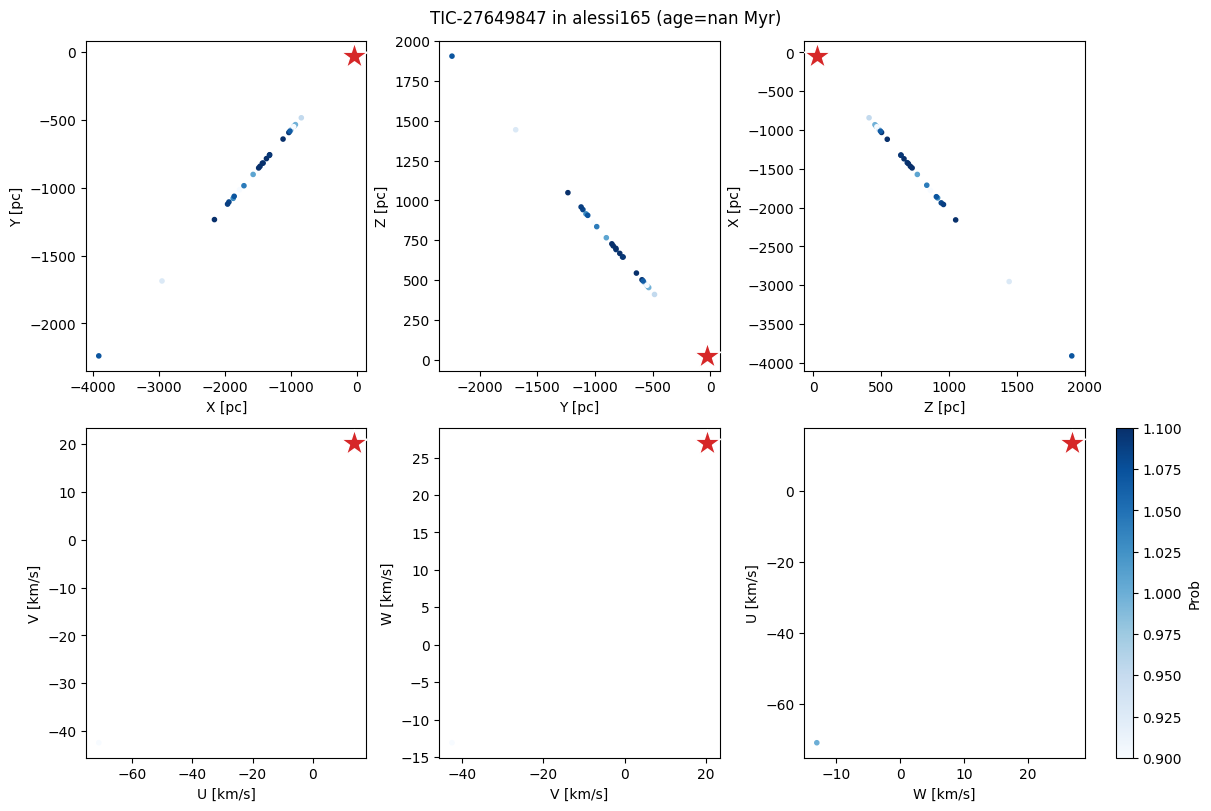

In [25]:
from wakai.catalog import plot_xyz_uvw

n = 0
ticid = df_final["TIC"].values[n]
age = df_final["matched_Age_[Myr]"].values[n]
cname = df_final["matched_Name"].values[n]

df_target = df_match.query("TIC==@ticid").squeeze()
d = df_mem.groupby("Name").get_group(cname)

fig, ax = plot_xyz_uvw(d, 
                       color='Prob', 
                       df_target=df_target,
                       target_color="C3",
                       target_ms=20,
                       marker='.',
                       cmap="Blues");
fig.suptitle(f"TIC-{int(ticid)} in {cname} (age={age:.0f} Myr)")

2026-05-12 08:54:11.916 | ERROR    | catalog:plot_rdp_pmrv:2099 - Error: 
2026-05-12 08:54:11.919 | ERROR    | catalog:plot_rdp_pmrv:2103 - Error: 


Text(0.5, 0.98, 'TIC-353475866 in cwnu3177')

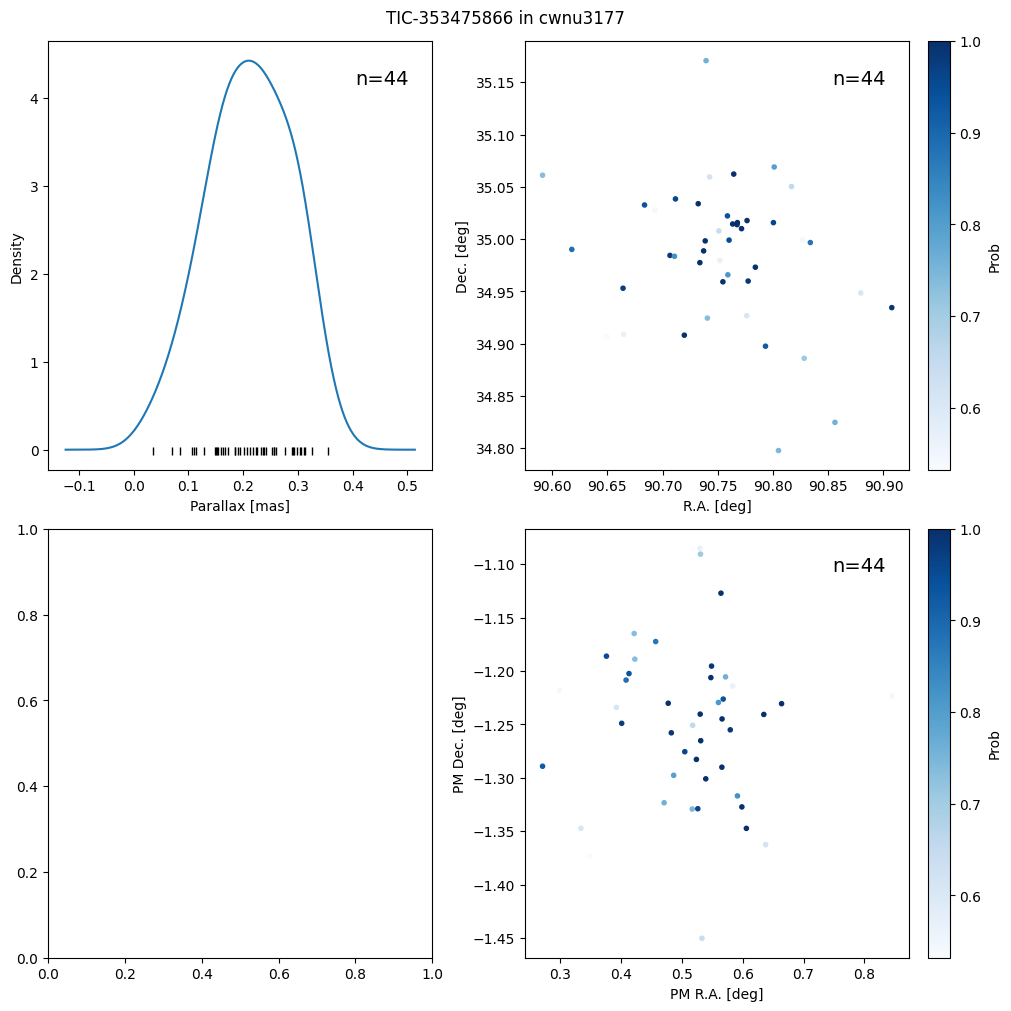

In [27]:
from wakai.catalog import plot_rdp_pmrv

ticid = 353475866
df_target = df_match.query("TIC==@ticid").squeeze()
age = df_target["matched_Age_[Myr]"]
cname = df_target["matched_Name"]
d = df_mem.groupby("Name").get_group(cname)

fig = plot_rdp_pmrv(d,
                   color='Prob', 
                    # target_gaiaid=6000286264203417600,
                    match_id=False,
                   df_target=df_target,
                   target_color="C3",
                   marker='.',
                   cmap="Blues");
fig.suptitle(f"TIC-{int(ticid)} in {cname}")

In [ ]:
import matplotlib.pyplot as pl
from wakai.catalog import plot_rdp_pmrv
from wakai.catalog import plot_xyz_uvw

outdir = '../output/Kunimoto25_pc_near_clusters'
groups = df_mem.groupby("Name")
for i,row in df_final.iterrows():
    try:
        ticid = row.TIC
        df_target = df_match.query("TIC==@ticid").squeeze()
        cname = row["matched_Name"]
        age = row["matched_Age_[Myr]"]
        d = groups.get_group(cname)
        
        # if len(d.radial_velocity.dropna())<10:
        #     print(f"Skipping TIC {ticid}")
        #     continue
        fp = f'{outdir}/TIC-{ticid}_in_{cname}_{age:.0f}Myr'
        if False:
            target_gaiaid = row['GaiaDR3']
            fig = plot_rdp_pmrv(d,
                               color='Prob', 
                               target_gaiaid=target_gaiaid,
                               match_id=False,
                               df_target=df_target,
                               target_color="C3",
                               marker='.',
                               cmap="Blues");
            fp=fp+'.png'
        else:
            fig, ax = plot_xyz_uvw(d, 
                               color='Prob', 
                               df_target=df_target,
                               target_color="C3",
                               target_ms=20,
                               marker='.',
                               cmap="Blues",
                               verbose=False
                              );
            fp=fp+'_xyzuvw.png'
        fig.suptitle(f"TIC-{ticid} in {cname} ({age:.0f} Myr)")
        print(f"https://ucc.ar/_clusters/{cname}")
        fig.savefig(fp, bbox_inches='tight', dpi=200)
        # pl.show()
    except Exception as e:
        print(e)